In [ ]:
### --- PLOTTING TOOLS --- ###

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.axes import Axes
from matplotlib.patches import Ellipse
import numpy as np

# Plotting tools


def plot_points(centroids, ax: Axes, color="red", marker="o", size=4, label=""):
    ax.scatter(
        centroids[:, 0],
        centroids[:, 1],
        s=size,
        marker=marker,
        c=color,
        label=label,
        alpha=1,
    )


def plot_evaluation_points(points, ax: Axes, color="black", marker="o"):
    ax.scatter(points[:, 0], points[:, 1], s=20, marker=marker, c=color)

    # Also plot visual labels (letters) for each point
    shift = 0.02
    import string

    letters = list(string.ascii_uppercase)

    for j in range(len(points)):
        x = points[j, 0] + shift
        y = points[j, 1] + shift
        ax.text(x, y, letters[j], horizontalalignment="left")


def plot_ellipses(ellipses, ax: Axes, plot_numbers=False):
    for j, ellipse in enumerate(ellipses):
        ax.add_patch(ellipse)

    # Plot ellipse numbers
    if plot_numbers:
        shift = 0.02
        for j in range(len(ellipses)):
            xy = ellipses[j].get_center()
            x = xy[0] + shift
            y = xy[1] + shift
            ax.text(x, y, f"{j + 1}", horizontalalignment="left")


def convert_to_ellipse_object(
    Q: np.array, centroid: np.array, color="red", alpha=0.3, filled=True
):
    D, U = np.linalg.eigh(Q)
    order = np.argsort(D)
    D = D[order]
    U = U[:, order]
    # Length of axes are lambda_i^{-0.5}.
    # So total diameter is 2 / D**(1/2).
    lengths = 2.0 / np.sqrt(D + 1e-12)
    width = lengths[0]
    height = lengths[1]
    # Angle is given by the rotation matrix U.
    # In particular, the first singular vector (which corresponds to the width)
    v0 = U[:, 0]
    angle = np.degrees(np.arctan2(v0[1], v0[0]))
    if filled:
        return Ellipse(
            xy=centroid,
            width=width,
            height=height,
            angle=angle,
            color=color,
            alpha=alpha,
        )
    else:
        return Ellipse(
            xy=centroid,
            width=width,
            height=height,
            angle=angle,
            alpha=1,
            facecolor="none",
            edgecolor=color,
            linewidth=1,
            # linestyle='dotted'
        )


mpl.rcParams.update(mpl.rcParamsDefault)

In [3]:
### --- DEFAULT PLOT SETTINGS --- ###
"""
mpl.rcParams.update({
    # --- Figure ---
    "figure.figsize": (3.4, 2.4),   # good for single-column papers
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,

    # --- Fonts ---
    "font.size": 7,
    "axes.titlesize": 6,
    "axes.labelsize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,

    # Use LaTeX-like serif fonts (great for papers)
    "font.family": "serif",
    # "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    # "mathtext.fontset": "dejavuserif",

    # --- Axes ---
    "axes.linewidth": 0.8,
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,

    # --- Ticks ---
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 1.5,
    "ytick.minor.size": 1.5,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    # --- Lines ---
    "lines.linewidth": 1.5,
    "lines.markersize": 2,

    # --- Legend ---
    "legend.frameon": False,

    # --- PDF/Vector friendliness ---
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
"""

'\nmpl.rcParams.update({\n    # --- Figure ---\n    "figure.figsize": (3.4, 2.4),   # good for single-column papers\n    "figure.dpi": 300,\n    "savefig.dpi": 300,\n    "savefig.bbox": "tight",\n    "savefig.pad_inches": 0.02,\n\n    # --- Fonts ---\n    "font.size": 7,\n    "axes.titlesize": 6,\n    "axes.labelsize": 6,\n    "xtick.labelsize": 6,\n    "ytick.labelsize": 6,\n    "legend.fontsize": 6,\n\n    # Use LaTeX-like serif fonts (great for papers)\n    "font.family": "serif",\n    # "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],\n    # "mathtext.fontset": "dejavuserif",\n\n    # --- Axes ---\n    "axes.linewidth": 0.8,\n    "axes.grid": False,\n    "axes.spines.top": False,\n    "axes.spines.right": False,\n\n    # --- Ticks ---\n    "xtick.direction": "in",\n    "ytick.direction": "in",\n    "xtick.major.size": 3,\n    "ytick.major.size": 3,\n    "xtick.minor.size": 1.5,\n    "ytick.minor.size": 1.5,\n    "xtick.major.width": 0.8,\n    "ytick.major.width": 0.8,\n\

In [4]:
### --- CLUSTER TOOLS --- ###

from scipy.spatial import ConvexHull


# Each of the following sampling functions are centered at origin and are based on unit ball
# In other words, no ellipses
def generate_unit_ball_points_uniform(N, d=2):
    directions = np.random.randn(N, d)
    directions /= np.linalg.norm(directions, axis=1)[:, None]
    radii = np.random.random(N) ** (1 / d)
    return directions * radii[:, None]


def generate_unit_ball_points_boundary_uniform(N, d=2):
    directions = np.random.randn(N, d)
    directions /= np.linalg.norm(directions, axis=1)[:, None]
    return directions


def generate_random_polytope(V, N, d=2):
    # Generate vertices and candidate points
    candidates = generate_unit_ball_points_uniform(N, d)
    polytope_vertices = generate_unit_ball_points_boundary_uniform(V, d)

    # Build convex hull
    convex_hull = ConvexHull(polytope_vertices)
    equations = convex_hull.equations
    A = equations[:, :-1]
    b = equations[:, -1]

    # Test candidates: a point is in if Ax + b < 0.
    in_half_plane = ((candidates @ A.T) + b) < 0
    in_conv_hull_msk = in_half_plane.all(axis=1)
    polytope_points = candidates[in_conv_hull_msk]
    return polytope_points


def matrix_sqrt(Q):
    D, U = np.linalg.eigh(Q)
    return (U * (np.abs(D) ** 0.5)) @ U.T

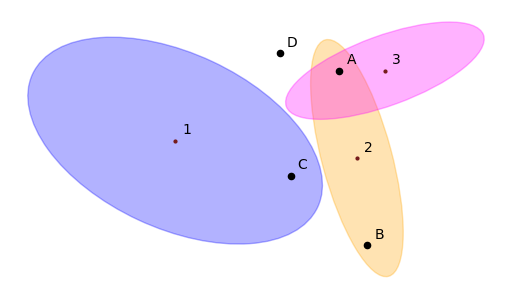

In [5]:
### --- FIGURE 1: Inference description --- ###

# Centroids and trust ellipses
centroids = np.array(
    [
        [0.4, 0.6],  # 1
        [0.92, 0.55],  # 2
        [1.0, 0.8],  # 3
    ]
)
centroid_color = "#751A1A"
ellipse_colors = ["blue", "orange", "magenta"]
trust_ellipses = [
    Ellipse(
        centroids[0],
        width=0.9,
        height=0.5,
        angle=-25,
        alpha=0.3,
        color=ellipse_colors[0],
    ),
    Ellipse(
        centroids[1],
        width=0.2,
        height=0.7,
        angle=15,
        alpha=0.3,
        color=ellipse_colors[1],
    ),
    Ellipse(
        centroids[2],
        width=0.6,
        height=0.2,
        angle=20,
        alpha=0.3,
        color=ellipse_colors[2],
    ),
]

# Example evaluation points
eval_points = np.array(
    [
        [0.87, 0.8],  # A
        [0.95, 0.3],  # B
        [0.73, 0.5],  # C
        [0.7, 0.85],  # D
    ]
)
eval_color = "black"

# Setting up first figure
fig1, ax1 = plt.subplots()
ax1.set_aspect("equal")
ax1.axis("off")

# Plot centroids and trust regions
plot_ellipses(trust_ellipses, ax1, plot_numbers=True)
plot_points(centroids, ax1, centroid_color, "o")

# Plot evaluation points
plot_evaluation_points(eval_points, ax1, eval_color, "o")
fig1.savefig("figs/inference_vis.png")

plt.show()

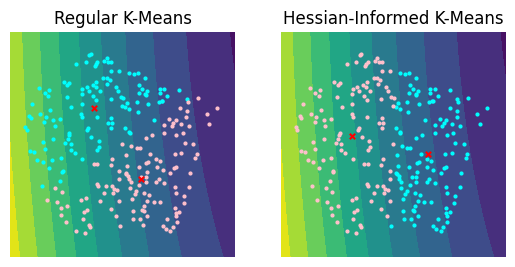

In [6]:
### --- FIGURE 2: Two-means clustering description --- ###
from src.problems.rosenbrock import rosenbrock, rosenbrock_grad, rosenbrock_hess

# Generate points in a cluster (convex region)
np.random.seed(6)
polytope_points = generate_random_polytope(8, 300)
# polytope_points = generate_unit_ball_points_uniform(250, d=2)
centroid = np.mean(polytope_points, axis=0)
centered_points = polytope_points - centroid

# Setting up second figure
fig2, ax2 = plt.subplots(1, 2)

# Underlying function for contours
s = 2
t = 2


def f(x, y):
    return 10 * (x - s) ** 2 + (y - t) ** 2


def grad_f(x, y):
    return np.column_stack((20 * (x - s), 2 * (y - t)))


def hess_f(x, y):  # just takes a single point
    return np.array([[20, 0], [0, 2]])


# def f(x, y):
#     return rosenbrock(np.column_stack((x,y)))
# def grad_f(x, y):
#     return rosenbrock_grad(np.column_stack((x,y)))
# def hess_f(x, y): # just takes a single point
#     return rosenbrock_hess(np.column_stack((x,y)))
x = np.linspace(-1.1, 1.1, 400)
X, Y = np.meshgrid(x, x)
Z = f(X, Y)

# Recluster the points

# A. K-Means (First eigenvector of covariance matrix, entire function)
_, _, V = np.linalg.svd(centered_points)
assign_msk_A = (centered_points @ V[0]) > 0
centroid_1A = np.mean(polytope_points[assign_msk_A], axis=0)
centroid_2A = np.mean(polytope_points[~assign_msk_A], axis=0)

# B. K-Means with fewer points (first evec of small covariance matrix)
# first compute error of points
f_centroid = f(centroid[0], centroid[1]).flatten()
g_centroid = grad_f(centroid[0], centroid[1]).flatten()
dx = polytope_points - centroid
linear_approx = f_centroid + dx @ g_centroid
exact = f(polytope_points[:, 0], polytope_points[:, 1]).flatten()
errors = np.abs(linear_approx - exact)
eps = 4
error_msk = errors < eps
# now compute covariance of the smaller matrix
centered_points_good_err = centered_points[error_msk]
_, _, V = np.linalg.svd(centered_points_good_err)
assign_msk_B = (polytope_points @ V[0]) > 0
centroid_1B = np.mean(polytope_points[assign_msk_B], axis=0)
centroid_2B = np.mean(polytope_points[~assign_msk_B], axis=0)

# C. Use Hessian
h_centroid = hess_f(centroid[0], centroid[1])
sqrt_h_centroid = matrix_sqrt(h_centroid).reshape(2, 2)
_, _, V = np.linalg.svd(centered_points @ sqrt_h_centroid)
assign_msk_C = (polytope_points @ V[0]) > 0
centroid_1C = np.mean(polytope_points[assign_msk_C], axis=0)
centroid_2C = np.mean(polytope_points[~assign_msk_C], axis=0)

# Plot the contours for each plot
for ax in ax2:
    ax.set_aspect("equal", adjustable="box")
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax.contourf(X, Y, Z, levels=10, cmap="viridis")


# Plot the points and other settings
c1 = "cyan"
c2 = "pink"

# Plot A
plot_points(polytope_points[assign_msk_A], ax2[0], c1, "o")
plot_points(polytope_points[~assign_msk_A], ax2[0], c2, "o")
ax2[0].axis("off")
ax2[0].set_title("Regular K-Means")
ax2[0].scatter(centroid_1A[0], centroid_1A[1], c="red", marker="x", s=15)
ax2[0].scatter(centroid_2A[0], centroid_2A[1], c="red", marker="x", s=15)
# Plot B
# plot_points(polytope_points[assign_msk_B],  ax2[1], c1, 'o')
# plot_points(polytope_points[~assign_msk_B], ax2[1], c2, 'o')
# Plot C
plot_points(polytope_points[assign_msk_C], ax2[1], c1, "o")
plot_points(polytope_points[~assign_msk_C], ax2[1], c2, "o")
ax2[1].axis("off")
ax2[1].set_title("Hessian-Informed K-Means")
ax2[1].scatter(centroid_1C[0], centroid_1C[1], c="red", marker="x", s=15)
ax2[1].scatter(centroid_2C[0], centroid_2C[1], c="red", marker="x", s=15)

plt.show()
fig2.savefig("hessian_kmeans.png")

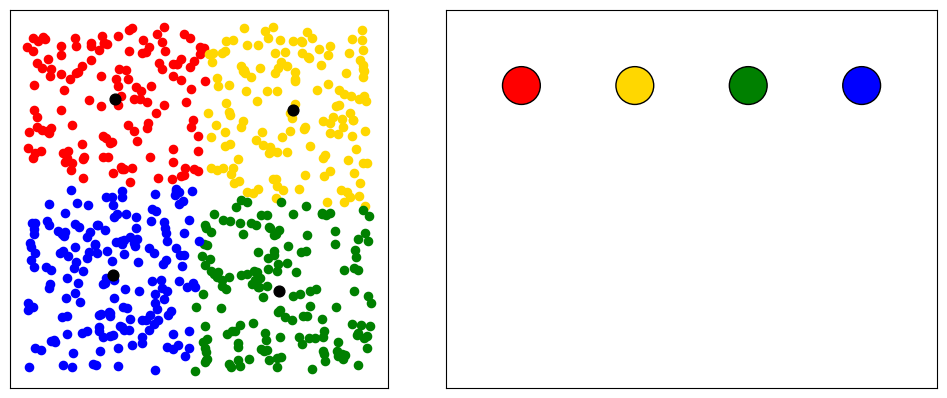

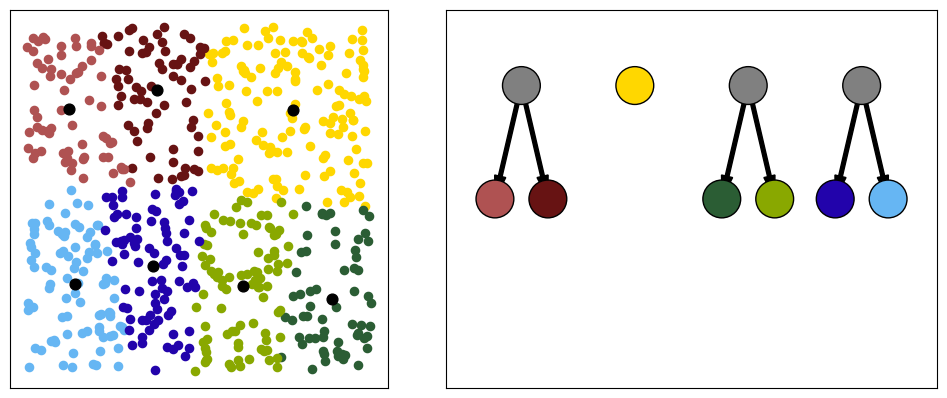

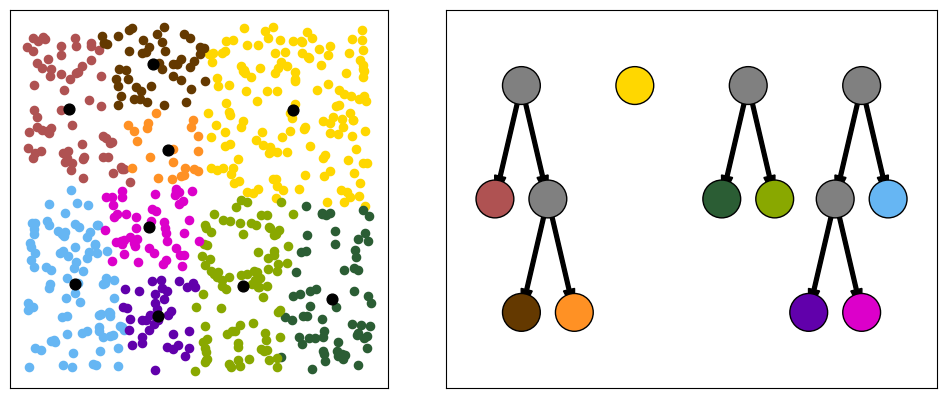

In [28]:
### --- FIGURE 3: Tree Figure --- ###

from src.adaptive_clustering import adaptive_clustering
from matplotlib.patches import Circle, Arrow
from sklearn.cluster import KMeans

# Training data
np.random.seed(0)
N_train = 600
train_data = np.random.uniform(0, 1, (N_train, 2))

# tree specifications
sw_offset = 0.07
vt_offset = 0.3
init_xloc = [0.2, 0.5, 0.8, 1.1]
tree_lvls = [0.8, 0.5, 0.2]
circ_radius = 0.05
width = init_xloc[0] + init_xloc[-1]


# extremely slow (with for loop) but fine for plotting
def _assign_labels(sources, targets):
    assignments = np.zeros(len(targets))
    for j, target in enumerate(targets):
        assignments[j] = np.argmin(np.linalg.norm(sources - target, 2, axis=1))
    return assignments


dotsize = 35
centroidsize = 60
colors = [
    "red",
    "gold",
    "green",
    "blue",
    "#671313",
    "#af5252",
    "#2b5d34",
    "#89a800",
    "#66b6f3",
    "#2203ab",
    "#643900",
    "#ff9124",
    "#6100ab",
    "#dc00ca",
]

fig1, axs1 = plt.subplots(
    nrows=1, ncols=2, gridspec_kw={"width_ratios": [1, width]}, figsize=(10, 10)
)
fig1.tight_layout()
fig2, axs2 = plt.subplots(
    nrows=1, ncols=2, gridspec_kw={"width_ratios": [1, width]}, figsize=(10, 10)
)
fig2.tight_layout()
fig3, axs3 = plt.subplots(
    nrows=1, ncols=2, gridspec_kw={"width_ratios": [1, width]}, figsize=(10, 10)
)
fig3.tight_layout()

# Original clusters
km = KMeans(n_clusters=4, random_state=0)
labels_lvl1 = km.fit_predict(train_data)
centroids_lvl1 = km.cluster_centers_
redpts = train_data[labels_lvl1 == 0]
yellowpts = train_data[labels_lvl1 == 3]
greenpts = train_data[labels_lvl1 == 2]
bluepts = train_data[labels_lvl1 == 1]

# Plot original clusters
plot_points(redpts, axs1[0], colors[0], size=dotsize)
plot_points(yellowpts, axs1[0], colors[1], size=dotsize)
plot_points(greenpts, axs1[0], colors[2], size=dotsize)
plot_points(bluepts, axs1[0], colors[3], size=dotsize)
plot_points(centroids_lvl1, axs1[0], "black", size=centroidsize)

# Make the corresponding tree
circles = [
    Circle(
        (init_xloc[0], tree_lvls[0]),
        circ_radius,
        facecolor=colors[0],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[1], tree_lvls[0]),
        circ_radius,
        facecolor=colors[1],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[2], tree_lvls[0]),
        circ_radius,
        facecolor=colors[2],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[3], tree_lvls[0]),
        circ_radius,
        facecolor=colors[3],
        edgecolor="black",
    ),
]
for circle in circles:
    axs1[1].add_patch(circle)


# Plot second level
km2 = KMeans(n_clusters=2, random_state=0)
# Recluster red
labels_red_lvl2 = km2.fit_predict(redpts)
centroids_red_lvl2 = km2.cluster_centers_
redpts_lvl2_0 = redpts[labels_red_lvl2 == 1]
redpts_lvl2_1 = redpts[labels_red_lvl2 == 0]
# Recluster green
km2 = KMeans(n_clusters=2, random_state=0)
labels_green_lvl2 = km2.fit_predict(greenpts)
centroids_green_lvl2 = km2.cluster_centers_
greenpts_lvl2_0 = greenpts[labels_green_lvl2 == 0]
greenpts_lvl2_1 = greenpts[labels_green_lvl2 == 1]
# Recluster blue
km2 = KMeans(n_clusters=2, random_state=0)
labels_blue_lvl2 = km2.fit_predict(bluepts)
centroids_blue_lvl2 = km2.cluster_centers_
bluepts_lvl2_0 = bluepts[labels_blue_lvl2 == 1]
bluepts_lvl2_1 = bluepts[labels_blue_lvl2 == 0]
centroids_lvl2 = np.vstack(
    (centroids_green_lvl2, centroids_red_lvl2, centroids_blue_lvl2, centroids_lvl1[3])
)

# Plot
plot_points(yellowpts, axs2[0], colors[1], size=dotsize)
plot_points(redpts_lvl2_0, axs2[0], colors[4], size=dotsize)
plot_points(redpts_lvl2_1, axs2[0], colors[5], size=dotsize)
plot_points(greenpts_lvl2_0, axs2[0], colors[6], size=dotsize)
plot_points(greenpts_lvl2_1, axs2[0], colors[7], size=dotsize)
plot_points(bluepts_lvl2_0, axs2[0], colors[8], size=dotsize)
plot_points(bluepts_lvl2_1, axs2[0], colors[9], size=dotsize)
plot_points(centroids_lvl2, axs2[0], "black", size=centroidsize)

# Make the tree for the second plot
lines = [
    Arrow(
        init_xloc[0],
        tree_lvls[0],
        -sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[0],
        tree_lvls[0],
        sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[2],
        tree_lvls[0],
        -sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[2],
        tree_lvls[0],
        sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[3],
        tree_lvls[0],
        -sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[3],
        tree_lvls[0],
        sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
]
circles = [
    # top level
    Circle((init_xloc[0], tree_lvls[0]), 0.05, facecolor="grey", edgecolor="black"),
    Circle((init_xloc[1], tree_lvls[0]), 0.05, facecolor=colors[1], edgecolor="black"),
    Circle((init_xloc[2], tree_lvls[0]), 0.05, facecolor="grey", edgecolor="black"),
    Circle((init_xloc[3], tree_lvls[0]), 0.05, facecolor="grey", edgecolor="black"),
    # next level
    Circle(
        (init_xloc[0] - sw_offset, tree_lvls[1]),
        0.05,
        facecolor=colors[5],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[0] + sw_offset, tree_lvls[1]),
        0.05,
        facecolor=colors[4],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[2] - sw_offset, tree_lvls[1]),
        0.05,
        facecolor=colors[6],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[2] + sw_offset, tree_lvls[1]),
        0.05,
        facecolor=colors[7],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[3] - sw_offset, tree_lvls[1]),
        0.05,
        facecolor=colors[9],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[3] + sw_offset, tree_lvls[1]),
        0.05,
        facecolor=colors[8],
        edgecolor="black",
    ),
]
for line in lines:
    axs2[1].add_patch(line)
for circle in circles:
    axs2[1].add_patch(circle)


# Plot third level

# Recluster dark red
km3 = KMeans(n_clusters=2, random_state=0)
labels_red_lvl3 = km3.fit_predict(redpts_lvl2_0)
centroids_red_lvl3 = km3.cluster_centers_
redpts_lvl3_0 = redpts_lvl2_0[labels_red_lvl3 == 0]
redpts_lvl3_1 = redpts_lvl2_0[labels_red_lvl3 == 1]
# Recluster dark blue
km3 = KMeans(n_clusters=2, random_state=0)
labels_blue_lvl3 = km3.fit_predict(bluepts_lvl2_1)
centroids_blue_lvl3 = km3.cluster_centers_
bluepts_lvl3_0 = bluepts_lvl2_1[labels_blue_lvl3 == 0]
bluepts_lvl3_1 = bluepts_lvl2_1[labels_blue_lvl3 == 1]
centroids_lvl3 = np.vstack(
    (
        centroids_red_lvl3,
        centroids_blue_lvl3,
        centroids_green_lvl2,
        centroids_red_lvl2[0],
        centroids_blue_lvl2[1],
        centroids_lvl1[3],
    )
)

# Plot
plot_points(yellowpts, axs3[0], colors[1], size=dotsize)
plot_points(redpts_lvl2_1, axs3[0], colors[5], size=dotsize)
plot_points(greenpts_lvl2_0, axs3[0], colors[6], size=dotsize)
plot_points(greenpts_lvl2_1, axs3[0], colors[7], size=dotsize)
plot_points(bluepts_lvl2_0, axs3[0], colors[8], size=dotsize)
plot_points(redpts_lvl3_0, axs3[0], colors[10], size=dotsize)
plot_points(redpts_lvl3_1, axs3[0], colors[11], size=dotsize)
plot_points(bluepts_lvl3_0, axs3[0], colors[12], size=dotsize)
plot_points(bluepts_lvl3_1, axs3[0], colors[13], size=dotsize)
plot_points(centroids_lvl3, axs3[0], "black", size=centroidsize)


# Make the tree for the third plot
lines = [
    Arrow(
        init_xloc[0],
        tree_lvls[0],
        -sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[0],
        tree_lvls[0],
        sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[2],
        tree_lvls[0],
        -sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[2],
        tree_lvls[0],
        sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[3],
        tree_lvls[0],
        -sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[3],
        tree_lvls[0],
        sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[0] + sw_offset,
        tree_lvls[1],
        -sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[0] + sw_offset,
        tree_lvls[1],
        sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[3] - sw_offset,
        tree_lvls[1],
        -sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
    Arrow(
        init_xloc[3] - sw_offset,
        tree_lvls[1],
        sw_offset,
        -vt_offset,
        width=circ_radius,
        color="black",
    ),
]
circles = [
    Circle(
        (init_xloc[0], tree_lvls[0]), circ_radius, facecolor="grey", edgecolor="black"
    ),
    Circle(
        (init_xloc[1], tree_lvls[0]),
        circ_radius,
        facecolor=colors[1],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[2], tree_lvls[0]), circ_radius, facecolor="grey", edgecolor="black"
    ),
    Circle(
        (init_xloc[3], tree_lvls[0]), circ_radius, facecolor="grey", edgecolor="black"
    ),
    Circle(
        (init_xloc[0] - sw_offset, tree_lvls[1]),
        circ_radius,
        facecolor=colors[5],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[0] + sw_offset, tree_lvls[1]),
        circ_radius,
        facecolor="grey",
        edgecolor="black",
    ),
    Circle(
        (init_xloc[2] - sw_offset, tree_lvls[1]),
        circ_radius,
        facecolor=colors[6],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[2] + sw_offset, tree_lvls[1]),
        circ_radius,
        facecolor=colors[7],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[3] - sw_offset, tree_lvls[1]),
        circ_radius,
        facecolor="grey",
        edgecolor="black",
    ),
    Circle(
        (init_xloc[3] + sw_offset, tree_lvls[1]),
        circ_radius,
        facecolor=colors[8],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[0], tree_lvls[2]),
        circ_radius,
        facecolor=colors[10],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[0] + 2 * sw_offset, tree_lvls[2]),
        circ_radius,
        facecolor=colors[11],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[3] - 2 * sw_offset, tree_lvls[2]),
        circ_radius,
        facecolor=colors[12],
        edgecolor="black",
    ),
    Circle(
        (init_xloc[3], tree_lvls[2]),
        circ_radius,
        facecolor=colors[13],
        edgecolor="black",
    ),
]
for line in lines:
    axs3[1].add_patch(line)
for circle in circles:
    axs3[1].add_patch(circle)


for j in range(2):
    axs1[j].set_xticks([])
    axs1[j].set_yticks([])
    axs1[j].set_aspect("equal", adjustable="box")
    axs2[j].set_xticks([])
    axs2[j].set_yticks([])
    axs2[j].set_aspect("equal", adjustable="box")
    axs3[j].set_xticks([])
    axs3[j].set_yticks([])
    axs3[j].set_aspect("equal", adjustable="box")

    if j == 1:
        axs1[j].set_xlim(0, width)
        axs1[j].set_ylim(0, 1)
        axs2[j].set_xlim(0, width)
        axs2[j].set_ylim(0, 1)
        axs3[j].set_xlim(0, width)
        axs3[j].set_ylim(0, 1)


plt.show()

fig1.savefig("figs/tree_lvl1.svg", bbox_inches="tight", pad_inches=0)
fig2.savefig("figs/tree_lvl2.svg", bbox_inches="tight", pad_inches=0)
fig3.savefig("figs/tree_lvl3.svg", bbox_inches="tight", pad_inches=0)

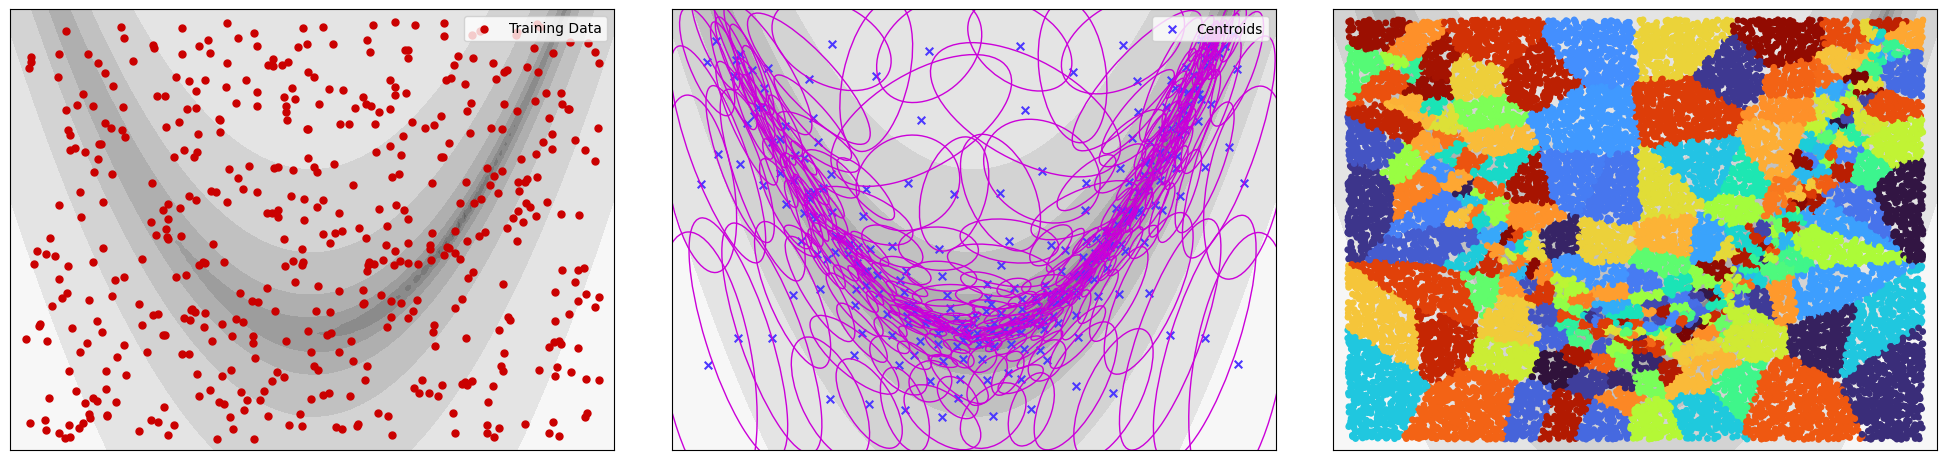

In [29]:
### --- FIGURE 4: Entire description of algorithm --- ###
"""
Underlying function: Rosenbrock 2D
Fig (a): input points
Fig (b): final points (centroids) after running algorithm
Fig (c): colored leaf clusters (input points but reclustered)
Fig (d): tree
"""

from src.surrogate import HATANNSurrogate
from src.problems.rosenbrock import rosenbrock, rosenbrock_grad
import matplotlib.colors as mcolors

# Training data
d = 2
N = 20000
X_train = np.column_stack((np.random.uniform(-2, 2, N), np.random.uniform(-1, 3, N)))

N_visual = 500
X_train_visual = np.column_stack(
    (np.random.uniform(-2, 2, N_visual), np.random.uniform(-1, 3, N_visual))
)

# Adaptive clustering parameters
N_init_clusters = 4
tol = 0.1

# Trained surrogate
surrogate = HATANNSurrogate(version="v2")
surrogate.train(
    X_train,
    f_fn=rosenbrock,
    g_fn=rosenbrock_grad,
    save_model=False,
    TOL=tol,
    ERROR_METRIC="Linf-local",
    NUM_INITIAL_CLUSTERS=N_init_clusters,
    MIN_PTS_PER_CLUSTER=15,
    MAX_CLUSTERS_EST=10000,
    SEED=1,
    USE_HESSIAN_INFORMED_SPLIT=True,
    IGNORE_GRADIENT=False,
    SAVE_GENERATED_TRAINING_DATA=True,
)

centroids = surrogate.get_source_centroids()
TRs = surrogate.get_trust_regions()

new_X_train = surrogate.training_data
p = np.random.permutation(len(centroids))
centroids = centroids[p]
TRs = TRs[p]

labels = _assign_labels(centroids, new_X_train)


# 2. Define Levels
levels = np.linspace(Z.min(), Z.max(), 10)

# plots
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
fig.tight_layout()

# gray colormap
cmap_gray = plt.get_cmap("gray")
new_cmap = mcolors.LinearSegmentedColormap.from_list(
    "truncated_gray", cmap_gray(np.linspace(0.3, 1.0, 100))
)

# contour data
x = np.linspace(-2.1, 2.1, 400)
y = np.linspace(-1.1, 3.1)
X, Y = np.meshgrid(x, y)
XY = np.column_stack([X.ravel(), Y.ravel()])
Z_flat = rosenbrock(XY, a=100)
Z = Z_flat.reshape(X.shape)

# Fig (a): training data
p = 0
ax[p].contourf(X, Y, np.log10(Z), levels=10, cmap=new_cmap)
# ax[p].contour(X, Y, np.log10(Z), levels=10, colors="black", linewidths=1.5, alpha=0.5, zorder=0)
# plot_points(X_train, ax[0], color="#CA0000", marker='o', label='Training Data', size=25)
plot_points(
    X_train_visual, ax[0], color="#CA0000", marker="o", label="Training Data", size=25
)
xlims = ax[p].get_xlim()
ylims = ax[p].get_ylim()
ax[p].legend(loc="upper right")
ax[p].set_xticks([])
ax[p].set_yticks([])

# Fig (b): centroids after running alg
p = 1
ellipses = []
for j, TR in enumerate(TRs):
    ellipses.append(
        convert_to_ellipse_object(TR, centroids[j], "#cb00d9", filled=False, alpha=0.7)
    )
ax[p].contourf(X, Y, np.log10(Z), levels=10, cmap=new_cmap)
# ax[p].contour(X, Y, np.log10(Z), levels=10, colors="black", linewidths=1.5, alpha=0.5, zorder=0)
plot_points(centroids, ax[p], color="#4C38FF", marker="x", size=30, label="Centroids")
plot_ellipses(ellipses, ax[p], False)
ax[p].set_xlim(xlims)
ax[p].set_ylim(ylims)
ax[p].legend(loc="upper right")
ax[p].set_xticks([])
ax[p].set_yticks([])

# Fig (c): colored input points (but reclustered)
p = 2
ax[p].contourf(X, Y, np.log10(Z), levels=10, cmap=new_cmap)
# ax[p].contour(X, Y, np.log10(Z), levels=10, colors="black", linewidths=1.5, alpha=0.5, zorder=0)
cmap = plt.get_cmap("turbo", len(centroids))
plot_colors = [cmap(x) for x in np.linspace(0, 1, len(centroids))]
ax[p].scatter(new_X_train[:, 0], new_X_train[:, 1], c=labels, cmap=cmap, s=15)
xlims = ax[0].get_xlim()
ylims = ax[0].get_ylim()
ax[p].set_xlim(xlims)
ax[p].set_ylim(ylims)
# plot_points(centroids, ax[p], color="#000000", marker='x', size=10)
# plot_ellipses(ellipses, ax[p], False)
ax[p].set_xticks([])
ax[p].set_yticks([])

plt.show()

fig.savefig("figs/ellipses_2_sideways.svg", bbox_inches="tight", pad_inches=0)